# SLAP-GRO — Phase 8: Picking Wave Layer & Order Batching

Notebook này phân tích cấu trúc của các đợt nhặt hàng (Picking Waves):
1. Thống kê phân bố 9,707 waves trong tập dữ liệu thực tế (Mode B).
2. Phân tích phân bố số lượt nhặt (picks/wave) và phân tầng không gian ($Z=1..4$).
3. Cơ chế tách rời siêu dữ liệu SKU để trích xuất `(depot, [locations])` chuẩn bị đầu vào cho GRO.
4. Tự động sinh 50 waves $\times$ 25 SKU tuân thủ phân bố Pareto cho Mode A (Paper Replication).


In [1]:
import sys, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path(os.getcwd()).resolve().parent if 'notebooks' in os.getcwd() else Path(os.getcwd()).resolve()
sys.path.insert(0, str(project_root / 'src'))

from slap_gro.picking.wave import PickingWaveDataset
from slap_gro.warehouse import build_warehouse
from slap_gro.picking.picking_points import build_gro_route_targets

# Nạp dataset picking waves thực tế
dataset = PickingWaveDataset.from_csv()
print(f'Nạp thành công {dataset.total_waves:,} picking waves ({dataset.total_items:,} lượt quét sản phẩm).')


Nạp thành công 9,707 picking waves (215,192 lượt quét sản phẩm).


Picks per wave: Mean = 22.2, Median = 24.0, Min = 1, Max = 30
Distinct locations per wave: Mean = 10.7, Median = 11.0


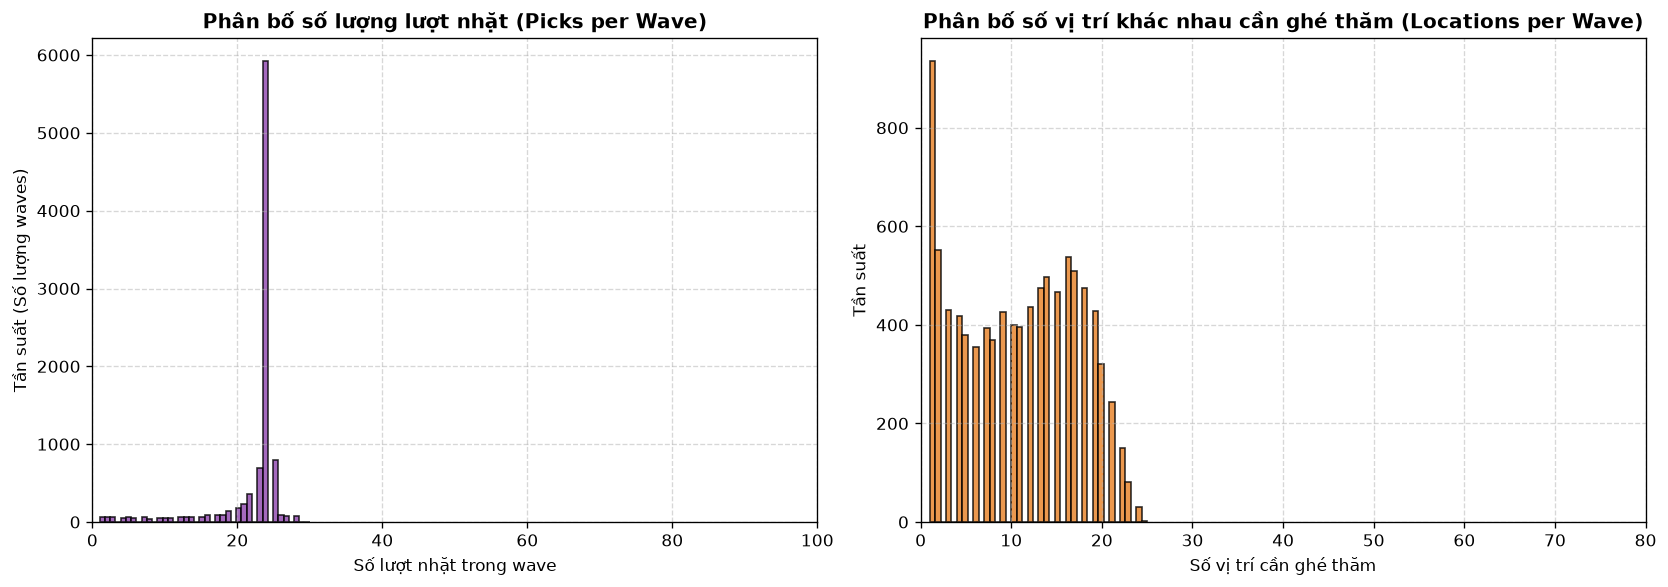

In [1]:
# Thống kê phân bố số lượt nhặt (picks) trên mỗi wave
wave_sizes = [len(w) for w in dataset.waves.values()]
sku_counts = [len(w.skus) for w in dataset.waves.values()]
loc_counts = [len(w.locations) for w in dataset.waves.values()]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(wave_sizes, bins=40, color='#8e44ad', edgecolor='black', alpha=0.8)
axes[0].set_title('Phân bố số lượng lượt nhặt (Picks per Wave)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Số lượt nhặt trong wave')
axes[0].set_ylabel('Tần suất (Số lượng waves)')
axes[0].set_xlim(0, 100)
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].hist(loc_counts, bins=40, color='#e67e22', edgecolor='black', alpha=0.8)
axes[1].set_title('Phân bố số vị trí khác nhau cần ghé thăm (Locations per Wave)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Số vị trí cần ghé thăm')
axes[1].set_ylabel('Tần suất')
axes[1].set_xlim(0, 80)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print(f'Picks per wave: Mean = {np.mean(wave_sizes):.1f}, Median = {np.median(wave_sizes):.1f}, Min = {np.min(wave_sizes)}, Max = {np.max(wave_sizes)}')
print(f'Distinct locations per wave: Mean = {np.mean(loc_counts):.1f}, Median = {np.median(loc_counts):.1f}')


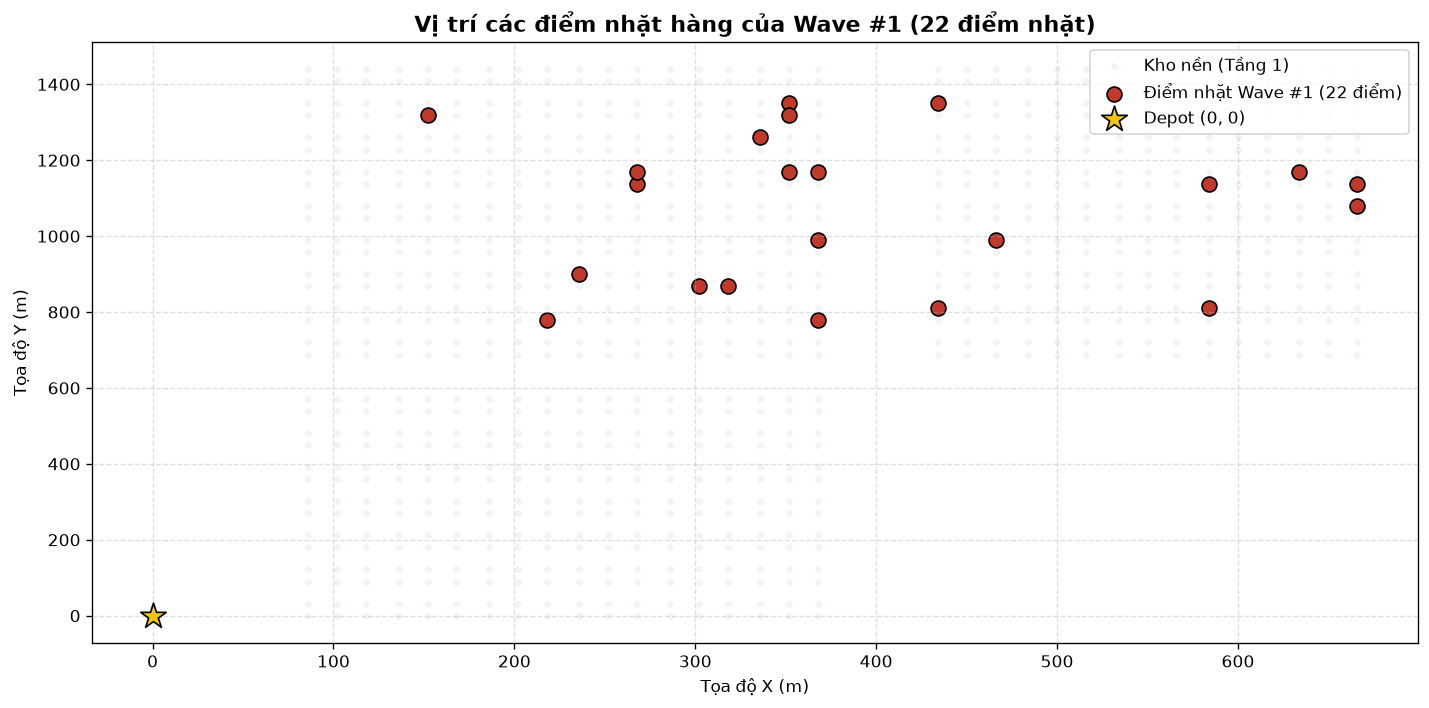

In [1]:
# Trực quan hóa tọa độ không gian các điểm nhặt hàng của Wave #1 trên mặt bằng kho
wh = build_warehouse('real')
sample_wave_id = dataset.wave_ids[0]
sample_wave = dataset.get(sample_wave_id)
depot, pick_locations = build_gro_route_targets(sample_wave, wh)

fig, ax = plt.subplots(figsize=(12, 6))

# Vẽ toàn bộ vị trí lưu trữ nền
bg_x = [loc.x for loc in wh.get_all_locations() if loc.z == 1]
bg_y = [loc.y for loc in wh.get_all_locations() if loc.z == 1]
ax.scatter(bg_x, bg_y, c='#ecf0f1', s=10, alpha=0.6, label='Kho nền (Tầng 1)')

# Vẽ các điểm nhặt của wave
pick_x = [loc.x for loc in pick_locations]
pick_y = [loc.y for loc in pick_locations]
ax.scatter(pick_x, pick_y, c='#c0392b', s=80, marker='o', edgecolors='black', label=f'Điểm nhặt Wave #{sample_wave_id} ({len(pick_locations)} điểm)')
ax.scatter([depot.x], [depot.y], c='#f1c40f', marker='*', s=260, edgecolors='black', label='Depot (0, 0)', zorder=6)

ax.set_title(f'Vị trí các điểm nhặt hàng của Wave #{sample_wave_id} ({len(pick_locations)} điểm nhặt)', fontsize=13, fontweight='bold')
ax.set_xlabel('Tọa độ X (m)')
ax.set_ylabel('Tọa độ Y (m)')
ax.legend(loc='upper right')
ax.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()
